Load data set


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paths to raw House 1 files
data_dir = Path("data/raw")

part1 = pd.read_csv(data_dir / "RAW_House1_Part1.csv")
part2 = pd.read_csv(data_dir / "RAW_House1_Part2.csv")

print("Part 1 shape:", part1.shape)
print("Part 2 shape:", part2.shape)

print(part1.head())
print(part1.columns.tolist())
print(part2.head())
print(part2.columns.tolist())

Part 1 shape: (4377877, 12)
Part 2 shape: (4140886, 12)
                  Time        Unix  Aggregate  Appliance1  Appliance2  \
0  2013-10-09 14:06:17  1381327577        523          74           0   
1  2013-10-09 14:06:31  1381327591        526          75           0   
2  2013-10-09 14:06:46  1381327606        540          74           0   
3  2013-10-09 14:07:01  1381327621        532          74           0   
4  2013-10-09 14:07:15  1381327634        540          74           0   

   Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  \
0          69           0           0           0           0           0   
1          69           0           0           0           0           0   
2          68           0           0           0           0           0   
3          68           0           0           0           0           0   
4          69           0           0           0           0           0   

   Appliance9  
0           1  
1         

combine


In [4]:
df = pd.concat(
    [part1, part2],
    ignore_index=True
)

print("Combined shape:", df.shape)
print(df.head())

Combined shape: (8518763, 12)
                  Time        Unix  Aggregate  Appliance1  Appliance2  \
0  2013-10-09 14:06:17  1381327577      523.0        74.0         0.0   
1  2013-10-09 14:06:31  1381327591      526.0        75.0         0.0   
2  2013-10-09 14:06:46  1381327606      540.0        74.0         0.0   
3  2013-10-09 14:07:01  1381327621      532.0        74.0         0.0   
4  2013-10-09 14:07:15  1381327634      540.0        74.0         0.0   

   Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  \
0        69.0         0.0         0.0         0.0         0.0         0.0   
1        69.0         0.0         0.0         0.0         0.0         0.0   
2        68.0         0.0         0.0         0.0         0.0         0.0   
3        68.0         0.0         0.0         0.0         0.0         0.0   
4        69.0         0.0         0.0         0.0         0.0         0.0   

   Appliance9  
0         1.0  
1         1.0  
2         1.0  
3   

inspect data quality

In [5]:
print("Dataset dimensions:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate complete rows:",
      df.duplicated().sum())

print("\nFirst timestamps:")
print(df["Time"].head())

print("\nLast timestamps:")
print(df["Time"].tail())

Dataset dimensions: (8518763, 12)

Data types:
Time           object
Unix            int64
Aggregate     float64
Appliance1    float64
Appliance2    float64
Appliance3    float64
Appliance4    float64
Appliance5    float64
Appliance6    float64
Appliance7    float64
Appliance8    float64
Appliance9    float64
dtype: object

Missing values:
Time                0
Unix                0
Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64

Duplicate complete rows: 595940

First timestamps:
0    2013-10-09 14:06:17
1    2013-10-09 14:06:31
2    2013-10-09 14:06:46
3    2013-10-09 14:07:01
4    2013-10-09 14:07:15
Name: Time, dtype: object

Last timestamps:
8518758    2015-07-10 11:56:05
8518759    2015-07-10 11:56:12
8518760    2015-07-10 11:56:18
8518761    2015-07-10 11:56:25
8518762    2015-07-10 11:56:32
Name:

In [6]:
df["Unix"] = pd.to_numeric(
    df["Unix"], errors="coerce"
)

df["Time"] = pd.to_datetime(
    df["Time"],
    dayfirst=True,
    errors="coerce"
)

print("Invalid timestamps:", df["Time"].isna().sum())
print("Missing Unix values:", df["Unix"].isna().sum())

Invalid timestamps: 5227894
Missing Unix values: 0


sort 

In [7]:
df = df.dropna(subset=["Unix"])

df = df.sort_values("Unix")

# Remove only exact duplicate records
df = df.drop_duplicates()

df = df.reset_index(drop=True)

In [8]:
print(
    "Duplicate Unix timestamps:",
    df["Unix"].duplicated().sum()
)

Duplicate Unix timestamps: 436044


In [9]:
# Count total rows
print("Total rows:", len(df))

# Count unique Unix timestamps
print("Unique Unix timestamps:", df["Unix"].nunique())

# Display examples of duplicate timestamps
duplicates = df[
    df["Unix"].duplicated(keep=False)
].sort_values("Unix")

print(duplicates.head(10))

Total rows: 7743759
Unique Unix timestamps: 7307715
                   Time        Unix  Aggregate  Appliance1  Appliance2  \
18  2013-09-10 14:08:45  1381327725      628.0        73.0         0.0   
19  2013-09-10 14:08:46  1381327725      628.0        73.0         0.0   
83  2013-09-10 14:15:16  1381328116     1392.0        70.0         0.0   
84  2013-09-10 14:15:17  1381328116     1392.0        70.0         0.0   
92  2013-09-10 14:16:15  1381328174     1338.0        70.0         0.0   
93  2013-09-10 14:16:14  1381328174     1338.0        70.0         0.0   
96  2013-09-10 14:16:31  1381328190     1329.0        69.0         0.0   
97  2013-09-10 14:16:30  1381328190     1329.0        69.0         0.0   
113 2013-09-10 14:18:17  1381328296     1269.0        68.0         0.0   
114 2013-09-10 14:18:16  1381328296     1269.0        68.0         0.0   

     Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  \
18          0.0         0.0         0.0         0.0   

In [10]:
# Check whether all columns are identical for duplicate timestamps
duplicate_groups = df.groupby("Unix").size()

print("Timestamps occurring more than once:",
      (duplicate_groups > 1).sum())

# Check whether duplicate Unix timestamps have different readings
different_readings = (
    df.groupby("Unix")["Aggregate"].nunique() > 1
).sum()

print("Timestamps with different Aggregate readings:",
      different_readings)

Timestamps occurring more than once: 412302
Timestamps with different Aggregate readings: 217376


In [11]:
print("Part 1 rows:", len(part1))
print("Part 2 rows:", len(part2))

print("Part 1 Unix range:",
      part1["Unix"].min(), part1["Unix"].max())

print("Part 2 Unix range:",
      part2["Unix"].min(), part2["Unix"].max())

Part 1 rows: 4377877
Part 2 rows: 4140886
Part 1 Unix range: 1381327577 1412126827
Part 2 Unix range: 1403906269 1436529392


In [12]:
for name, part in [("Part 1", part1), ("Part 2", part2)]:
    print(f"\n{name}")
    print("Total rows:", len(part))
    print("Unique Unix timestamps:", part["Unix"].nunique())
    print("Duplicate Unix rows:", part["Unix"].duplicated().sum())
    print("Exact duplicate rows:", part.duplicated().sum())


Part 1
Total rows: 4377877
Unique Unix timestamps: 3373473
Duplicate Unix rows: 1004404
Exact duplicate rows: 595935

Part 2
Total rows: 4140886
Unique Unix timestamps: 4126131
Duplicate Unix rows: 14755
Exact duplicate rows: 0


In [13]:
p1_min, p1_max = part1["Unix"].min(), part1["Unix"].max()
p2_min, p2_max = part2["Unix"].min(), part2["Unix"].max()

overlap_start = max(p1_min, p2_min)
overlap_end = min(p1_max, p2_max)

print("Overlap starts:", overlap_start)
print("Overlap ends:", overlap_end)
print("Overlap duration (days):",
      (overlap_end - overlap_start) / 86400)

# Number of shared Unix timestamps
shared_timestamps = set(part1["Unix"]) & set(part2["Unix"])

print("Shared Unix timestamps:", len(shared_timestamps))

Overlap starts: 1403906269
Overlap ends: 1412126827
Overlap duration (days): 95.14534722222223
Shared Unix timestamps: 191889


In [14]:
# Inspect rows with duplicate Unix timestamps in Part 1
dup_p1 = part1[
    part1["Unix"].duplicated(keep=False)
].sort_values(["Unix", "Time"])

print(
    dup_p1[
        ["Time", "Unix", "Aggregate",
         "Appliance1", "Appliance2"]
    ].head(20).to_string(index=False)
)

               Time       Unix  Aggregate  Appliance1  Appliance2
2013-10-09 14:08:45 1381327725        628          73           0
2013-10-09 14:08:46 1381327725        628          73           0
2013-10-09 14:15:16 1381328116       1392          70           0
2013-10-09 14:15:17 1381328116       1392          70           0
2013-10-09 14:16:14 1381328174       1338          70           0
2013-10-09 14:16:15 1381328174       1338          70           0
2013-10-09 14:16:30 1381328190       1329          69           0
2013-10-09 14:16:31 1381328190       1329          69           0
2013-10-09 14:18:16 1381328296       1269          68           0
2013-10-09 14:18:17 1381328296       1269          68           0
2013-10-09 14:18:59 1381328339       1723          69           0
2013-10-09 14:19:00 1381328339       1723          69           0
2013-10-09 14:19:28 1381328368       1833          47           0
2013-10-09 14:19:29 1381328368       1833          47           0
2013-10-09

In [15]:
print(
    "Duplicate Time rows in Part 1:",
    part1["Time"].duplicated().sum()
)

print(
    "Duplicate Time rows in Part 2:",
    part2["Time"].duplicated().sum()
)

Duplicate Time rows in Part 1: 645514
Duplicate Time rows in Part 2: 0


In [16]:
# Inspect the boundary between the two files
print("Part 1 final records:")
print(part1.tail(5)[["Time", "Unix", "Aggregate"]])

print("\nPart 2 initial records:")
print(part2.head(5)[["Time", "Unix", "Aggregate"]])

Part 1 final records:
                        Time        Unix  Aggregate
4377872  2014-10-01 01:26:38  1412126797        186
4377873  2014-10-01 01:26:51  1412126810        185
4377874  2014-10-01 01:26:52  1412126812        185
4377875  2014-10-01 01:27:07  1412126827        187
4377876  2014-10-01 01:27:07  1412126827        187

Part 2 initial records:
                  Time        Unix  Aggregate
0  2014-06-27 21:57:50  1403906269      322.0
1  2014-06-27 21:57:51  1403906271        NaN
2  2014-06-27 21:57:58  1403906278      329.0
3  2014-06-27 21:58:06  1403906286      322.0
4  2014-06-27 21:58:14  1403906293      320.0


In [17]:
# Convert Time to datetime format
part1["Time"] = pd.to_datetime(
    part1["Time"],
    errors="coerce"
)

# Convert Unix timestamps to datetime
unix_time = pd.to_datetime(
    pd.to_numeric(part1["Unix"], errors="coerce"),
    unit="s",
    utc=True,
    errors="coerce"
).dt.tz_localize(None)

# Compare timestamps
time_diff = (
    part1["Time"] - unix_time
).dt.total_seconds()

print("Time-Unix difference in seconds:")
print(time_diff.describe())

print(
    "Rows with difference greater than 1 second:",
    (time_diff.abs() > 1).sum()
)

print("\nExamples of mismatches:")
print(
    part1.loc[
        time_diff.abs() > 1,
        ["Time", "Unix"]
    ].head(10)
)

Time-Unix difference in seconds:
count    4.377877e+06
mean     4.874511e-01
std      4.998426e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64
Rows with difference greater than 1 second: 0

Examples of mismatches:
Empty DataFrame
Columns: [Time, Unix]
Index: []


In [18]:
part1_clean = part1.drop_duplicates().copy()
part2_clean = part2.drop_duplicates().copy()

print("Part 1 rows before:", len(part1))
print("Part 1 rows after:", len(part1_clean))

print("Part 2 rows before:", len(part2))
print("Part 2 rows after:", len(part2_clean))

Part 1 rows before: 4377877
Part 1 rows after: 3781942
Part 2 rows before: 4140886
Part 2 rows after: 4140886


In [19]:
df = pd.concat(
    [part1_clean, part2_clean],
    ignore_index=True
)

df["Unix"] = pd.to_numeric(
    df["Unix"], errors="coerce"
)

df = df.dropna(subset=["Unix"])
df = df.sort_values("Unix").reset_index(drop=True)

print("Combined rows:", len(df))
print("Unique Unix timestamps:", df["Unix"].nunique())
print("Duplicate Unix rows:", df["Unix"].duplicated().sum())

Combined rows: 7922828
Unique Unix timestamps: 7307715
Duplicate Unix rows: 615113


In [20]:
# Select timestamps appearing in both files
shared = pd.Index(part1_clean["Unix"].unique()).intersection(
    pd.Index(part2_clean["Unix"].unique())
)

print("Shared timestamps:", len(shared))

# Inspect overlapping records for a small sample
sample_ts = shared[:10]

print("\nPart 1 sample:")
print(
    part1_clean[part1_clean["Unix"].isin(sample_ts)]
    [["Time", "Unix", "Aggregate"]]
    .sort_values("Unix")
)

print("\nPart 2 sample:")
print(
    part2_clean[part2_clean["Unix"].isin(sample_ts)]
    [["Time", "Unix", "Aggregate"]]
    .sort_values("Unix")
)

Shared timestamps: 191889

Part 1 sample:
                       Time        Unix  Aggregate
3120026 2014-06-27 21:59:25  1403906364        324
3120029 2014-06-27 21:59:40  1403906380        322
3120030 2014-06-27 21:59:41  1403906380        322
3120032 2014-06-27 21:59:55  1403906395        317
3120040 2014-06-27 22:00:44  1403906443        323
3120043 2014-06-27 22:01:00  1403906460        318
3120045 2014-06-27 22:01:15  1403906475        325
3120048 2014-06-27 22:01:30  1403906490        323
3120060 2014-06-27 22:02:43  1403906562        372
3120063 2014-06-27 22:02:58  1403906577        364
3120072 2014-06-27 22:03:55  1403906634        367

Part 2 sample:
                   Time        Unix  Aggregate
13  2014-06-27 21:59:25  1403906364      319.0
15  2014-06-27 21:59:41  1403906380      320.0
17  2014-06-27 21:59:56  1403906395      317.0
23  2014-06-27 22:00:44  1403906443      321.0
26  2014-06-27 22:01:00  1403906460        NaN
28  2014-06-27 22:01:15  1403906475      321.0
3

In [21]:
power_cols = [
    "Aggregate",
    *[f"Appliance{i}" for i in range(1, 10)]
]

# Convert power columns to numeric
for col in power_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Count non-missing power readings in each row
df["valid_power_count"] = df[power_cols].notna().sum(axis=1)

# Examine duplicate Unix timestamps
duplicate_rows = df[df["Unix"].duplicated(keep=False)].copy()

print("Rows involved in duplicate timestamps:", len(duplicate_rows))

print("\nDistribution of valid power readings:")
print(duplicate_rows["valid_power_count"].value_counts().sort_index())

Rows involved in duplicate timestamps: 1187076

Distribution of valid power readings:
valid_power_count
1       7705
2       2455
3       2477
4       3108
5       6003
6      16837
7      42324
8      71979
9      67835
10    966353
Name: count, dtype: int64


In [22]:
# Count distinct aggregate readings for each Unix timestamp
aggregate_variants = (
    df.groupby("Unix")["Aggregate"].nunique(dropna=True)
)

print(
    "Timestamps with conflicting Aggregate values:",
    (aggregate_variants > 1).sum()
)

# Count timestamps with missing Aggregate values in any duplicate group
aggregate_missing_groups = (
    df.groupby("Unix")["Aggregate"].apply(lambda s: s.isna().any())
)

print(
    "Timestamp groups with a missing Aggregate reading:",
    aggregate_missing_groups.sum()
)

Timestamps with conflicting Aggregate values: 217376
Timestamp groups with a missing Aggregate reading: 188516


In [23]:
# Preserve the original row order for reproducible tie-breaking
df = df.reset_index(drop=True)
df["_original_order"] = range(len(df))

# Count available power measurements per row
power_cols = [
    "Aggregate",
    *[f"Appliance{i}" for i in range(1, 10)]
]

df["valid_power_count"] = df[power_cols].notna().sum(axis=1)

# Sort by timestamp, then completeness, then original order
df = df.sort_values(
    ["Unix", "valid_power_count", "_original_order"],
    ascending=[True, False, True],
    kind="stable"
)

# Retain one row per Unix timestamp
df_clean = df.drop_duplicates(
    subset="Unix",
    keep="first"
).copy()

# Remove helper columns
df_clean = df_clean.drop(
    columns=["valid_power_count", "_original_order"]
)

df_clean = df_clean.sort_values("Unix").reset_index(drop=True)

print("Rows before deduplication:", len(df))
print("Rows after deduplication:", len(df_clean))
print("Remaining duplicate Unix timestamps:",
      df_clean["Unix"].duplicated().sum())

Rows before deduplication: 7922828
Rows after deduplication: 7307715
Remaining duplicate Unix timestamps: 0


In [24]:
print("Missing readings by column:")
print(df_clean[power_cols].isna().sum())

print("\nMissing percentage by column:")
print((df_clean[power_cols].isna().mean() * 100).round(2))

Missing readings by column:
Aggregate      172827
Appliance1     401290
Appliance2     423096
Appliance3     282623
Appliance4     447095
Appliance5     455294
Appliance6     306743
Appliance7     206988
Appliance8     357479
Appliance9    1707453
dtype: int64

Missing percentage by column:
Aggregate      2.36
Appliance1     5.49
Appliance2     5.79
Appliance3     3.87
Appliance4     6.12
Appliance5     6.23
Appliance6     4.20
Appliance7     2.83
Appliance8     4.89
Appliance9    23.37
dtype: float64


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert Unix timestamp to datetime
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Unix"],
    unit="s",
    errors="coerce"
)

# Sort chronologically
df_clean = (
    df_clean.dropna(subset=["Datetime"])
    .sort_values("Datetime")
    .reset_index(drop=True)
)

# Calculate time between consecutive readings
df_clean["Interval_seconds"] = (
    df_clean["Datetime"].diff().dt.total_seconds()
)

print("Timestamp range:")
print("Start:", df_clean["Datetime"].min())
print("End:", df_clean["Datetime"].max())

print("\nInterval summary:")
print(df_clean["Interval_seconds"].describe())

print("\nInterval distribution:")
print(
    df_clean["Interval_seconds"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nIntervals greater than 60 seconds:",
      (df_clean["Interval_seconds"] > 60).sum())

print("Non-positive intervals:",
      (df_clean["Interval_seconds"] <= 0).sum())

Timestamp range:
Start: 2013-10-09 14:06:17
End: 2015-07-10 11:56:32

Interval summary:
count    7.307714e+06
mean     7.553910e+00
std      1.394744e+03
min      1.000000e+00
25%      4.000000e+00
50%      7.000000e+00
75%      8.000000e+00
max      3.594414e+06
Name: Interval_seconds, dtype: float64

Interval distribution:
Interval_seconds
1.0      134956
2.0     1229144
3.0      213878
4.0      438524
5.0      340122
6.0     1097095
7.0     1723366
8.0      762820
9.0      259948
10.0      41509
11.0     279129
12.0      25833
13.0     452585
14.0      40632
15.0     242655
16.0      14023
17.0       2496
18.0        818
19.0        786
20.0        648
Name: count, dtype: int64

Intervals greater than 60 seconds: 4040
Non-positive intervals: 0


In [26]:
# Use datetime as the index for resampling
df_time = df_clean.set_index("Datetime")

# Average readings within each minute
df_1min = df_time[power_cols].resample("1min").mean()

print("Rows before resampling:", len(df_clean))
print("Rows after resampling:", len(df_1min))

print("\nMissing values after resampling:")
print(df_1min.isna().sum())

print("\nFirst five minutes:")
print(df_1min.head())

Rows before resampling: 7307715
Rows after resampling: 920031

Missing values after resampling:
Aggregate     115134
Appliance1    117651
Appliance2    118517
Appliance3    116589
Appliance4    115999
Appliance5    123535
Appliance6    115969
Appliance7    115121
Appliance8    116775
Appliance9    212967
dtype: int64

First five minutes:
                      Aggregate  Appliance1  Appliance2  Appliance3  \
Datetime                                                              
2013-10-09 14:06:00  529.666667   74.333333         0.0   68.666667   
2013-10-09 14:07:00  543.875000   73.875000         0.0   68.750000   
2013-10-09 14:08:00  572.444444   73.111111         0.0   46.555556   
2013-10-09 14:09:00  638.300000   72.800000         0.0    0.000000   
2013-10-09 14:10:00  800.200000   72.000000         0.0    0.000000   

                     Appliance4  Appliance5  Appliance6  Appliance7  \
Datetime                                                              
2013-10-09 14:06:00 

In [27]:
# Identify minutes where Aggregate is missing
missing_aggregate = df_1min["Aggregate"].isna()

# Find consecutive missing-minute groups
group_id = missing_aggregate.ne(
    missing_aggregate.shift(fill_value=False)
).cumsum()

gap_lengths = (
    missing_aggregate[missing_aggregate]
    .groupby(group_id[missing_aggregate])
    .size()
)

print("Number of missing-minute gaps:", len(gap_lengths))
print("Gaps of 1-2 minutes:", (gap_lengths <= 2).sum())
print("Gaps longer than 2 minutes:", (gap_lengths > 2).sum())

Number of missing-minute gaps: 986
Gaps of 1-2 minutes: 538
Gaps longer than 2 minutes: 448


In [28]:
# Preserve the original one-minute resampled data
df_final = df_1min.copy()

# Create flags for missing Aggregate readings
missing = df_final["Aggregate"].isna()

# Identify consecutive missing-minute groups
group_id = missing.ne(
    missing.shift(fill_value=False)
).cumsum()

# Get the length of each missing group
gap_lengths = (
    missing[missing]
    .groupby(group_id[missing])
    .size()
)

# Find the IDs of gaps lasting 1-2 minutes
short_gap_ids = gap_lengths[gap_lengths <= 2].index

# Identify minutes belonging to short gaps
short_gap_mask = group_id.isin(short_gap_ids) & missing

print("Short-gap minutes:", short_gap_mask.sum())
print("Long-gap minutes:", missing.sum() - short_gap_mask.sum())

Short-gap minutes: 590
Long-gap minutes: 114544


In [29]:
power_cols = [
    "Aggregate",
    *[f"Appliance{i}" for i in range(1, 10)]
]

# Interpolate numeric readings in both directions,
# then use the mask to fill only identified short gaps
interpolated = df_final[power_cols].interpolate(
    method="time",
    limit_area="inside"
)

df_final.loc[short_gap_mask, power_cols] = interpolated.loc[
    short_gap_mask, power_cols
]

# Keep a flag for the longer Aggregate outages
df_final["Aggregate_long_outage"] = (
    df_final["Aggregate"].isna()
)

print("Aggregate missing after short-gap handling:",
      df_final["Aggregate"].isna().sum())

print("Long-outage minutes still unfilled:",
      df_final["Aggregate_long_outage"].sum())

Aggregate missing after short-gap handling: 114544
Long-outage minutes still unfilled: 114544


In [30]:
# Count negative readings
print("Negative readings by channel:")
print((df_final[power_cols] < 0).sum())

# Calculate IQR-based upper screening limits
for col in power_cols:
    series = df_final[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper_limit = q3 + 3 * iqr

    extreme_count = (series > upper_limit).sum()

    print(
        f"{col}: upper screening limit = {upper_limit:.2f} W, "
        f"extreme readings = {extreme_count}"
    )

Negative readings by channel:
Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64
Aggregate: upper screening limit = 1237.13 W, extreme readings = 49238
Appliance1: upper screening limit = 0.00 W, extreme readings = 199740
Appliance2: upper screening limit = 181.00 W, extreme readings = 508
Appliance3: upper screening limit = 278.67 W, extreme readings = 137
Appliance4: upper screening limit = 0.00 W, extreme readings = 4302
Appliance5: upper screening limit = 0.00 W, extreme readings = 19285
Appliance6: upper screening limit = 0.00 W, extreme readings = 7998
Appliance7: upper screening limit = 0.00 W, extreme readings = 93067
Appliance8: upper screening limit = 0.00 W, extreme readings = 150986
Appliance9: upper screening limit = 1.00 W, extreme readings = 57230


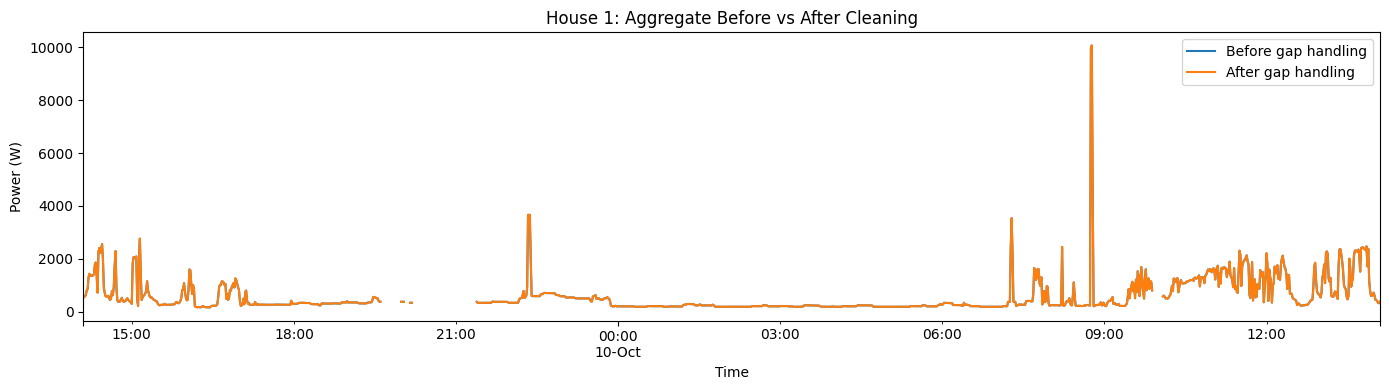

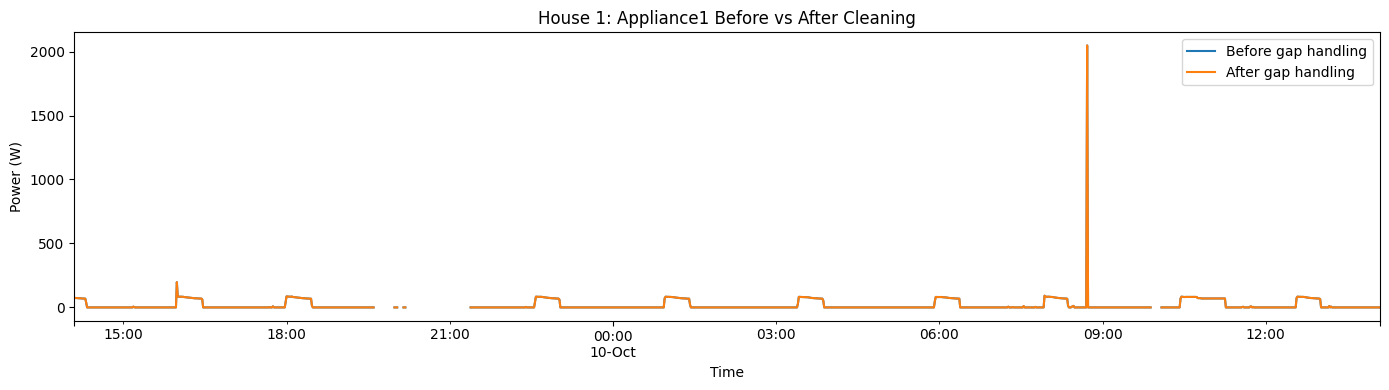

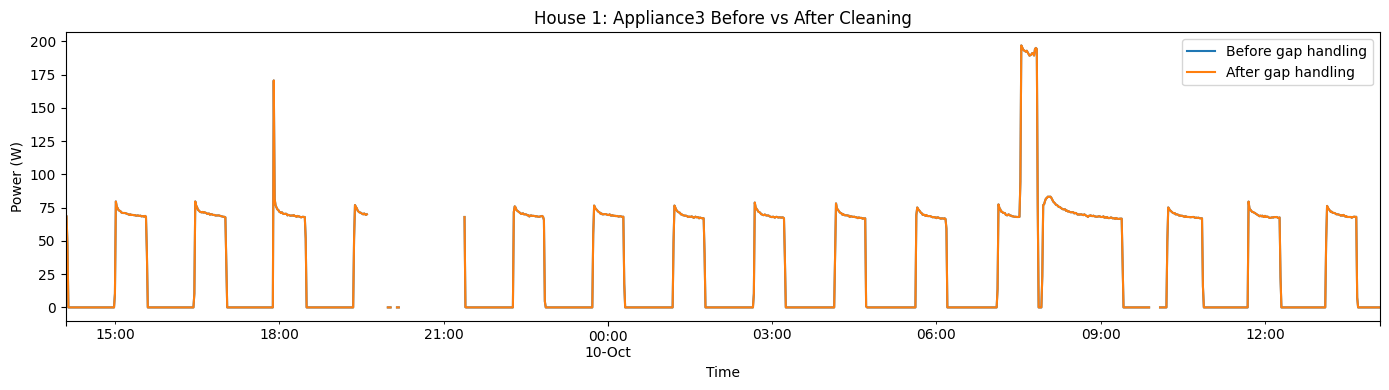

In [31]:
import matplotlib.pyplot as plt

start = df_1min.index.min()
end = start + pd.Timedelta(hours=24)

for col in ["Aggregate", "Appliance1", "Appliance3"]:
    fig, ax = plt.subplots(figsize=(14, 4))

    df_1min.loc[start:end, col].plot(
        ax=ax,
        label="Before gap handling"
    )

    df_final.loc[start:end, col].plot(
        ax=ax,
        label="After gap handling"
    )

    ax.set_title(f"House 1: {col} Before vs After Cleaning")
    ax.set_xlabel("Time")
    ax.set_ylabel("Power (W)")
    ax.legend()

    plt.tight_layout()
    plt.show()

In [32]:
# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Before": df_1min[power_cols].isna().sum(),
    "Missing_After": df_final[power_cols].isna().sum()
})

missing_summary["Before_%"] = (
    missing_summary["Missing_Before"]
    / len(df_1min) * 100
).round(2)

missing_summary["After_%"] = (
    missing_summary["Missing_After"]
    / len(df_final) * 100
).round(2)

print(missing_summary)

            Missing_Before  Missing_After  Before_%  After_%
Aggregate           115134         114544     12.51    12.45
Appliance1          117651         117071     12.79    12.72
Appliance2          118517         117936     12.88    12.82
Appliance3          116589         116010     12.67    12.61
Appliance4          115999         115414     12.61    12.54
Appliance5          123535         122956     13.43    13.36
Appliance6          115969         115389     12.60    12.54
Appliance7          115121         114541     12.51    12.45
Appliance8          116775         116196     12.69    12.63
Appliance9          212967         212379     23.15    23.08


In [33]:
import pandas as pd
import numpy as np

power_cols = [
    "Aggregate",
    "Appliance1", "Appliance2", "Appliance3",
    "Appliance4", "Appliance5", "Appliance6",
    "Appliance7", "Appliance8", "Appliance9"
]

# Inspect distribution of each power channel
print("POWER DISTRIBUTION")
print(
    df_1min[power_cols]
    .describe(percentiles=[0.95, 0.99, 0.999])
    .T
    .round(2)
)

POWER DISTRIBUTION
               count    mean     std    min     50%      95%      99%  \
Aggregate   804897.0  477.65  761.40  113.5  245.78  1415.33  3344.40   
Appliance1  802380.0   19.03  130.83    0.0    0.00    81.00    84.56   
Appliance2  801514.0   16.78   44.00    0.0    0.00    49.00    56.11   
Appliance3  803442.0   29.41   50.94    0.0    0.00    74.09    79.75   
Appliance4  804032.0    5.15  362.09    0.0    0.00     0.00     0.00   
Appliance5  796496.0   11.13  145.36    0.0    0.00     0.00   126.86   
Appliance6  804062.0   11.22  153.86    0.0    0.00     0.00     0.00   
Appliance7  804910.0    3.01  123.75    0.0    0.00    26.45    36.62   
Appliance8  803256.0    6.31   89.49    0.0    0.00    33.50    38.33   
Appliance9  707064.0   76.58  264.51    0.0    1.00   993.60  1023.11   

               99.9%       max  
Aggregate   10543.37  23965.75  
Appliance1    137.71  65549.00  
Appliance2    149.00  19660.20  
Appliance3    195.75  13247.40  
Appliance4  

In [34]:

# Identify consecutive minutes with unusually high Aggregate readings

aggregate = df_final["Aggregate"]

high_mask = aggregate > 10000

# Group consecutive high readings into separate events
event_id = (high_mask != high_mask.shift()).cumsum()

high_events = (
    df_final.loc[high_mask, ["Aggregate"]]
    .assign(Event=event_id[high_mask])
    .groupby("Event")
    .agg(
        Start=("Aggregate", lambda x: x.index.min()),
        End=("Aggregate", lambda x: x.index.max()),
        Duration_Minutes=("Aggregate", "size"),
        Peak_Aggregate=("Aggregate", "max")
    )
    .reset_index(drop=True)
)

print("Number of high-reading events:", len(high_events))
print("\nLongest high-reading events:")
print(
    high_events
    .sort_values("Duration_Minutes", ascending=False)
    .head(15)
    .to_string(index=False)
)


Number of high-reading events: 515

Longest high-reading events:
              Start                 End  Duration_Minutes  Peak_Aggregate
2015-02-08 13:22:00 2015-02-08 16:11:00               170    12505.000000
2014-11-18 21:37:00 2014-11-18 21:51:00                15    10569.000000
2014-05-31 23:49:00 2014-05-31 23:58:00                10    10958.714286
2014-12-22 08:01:00 2014-12-22 08:10:00                10    12141.555556
2014-12-24 11:23:00 2014-12-24 11:31:00                 9    23965.750000
2014-08-09 22:41:00 2014-08-09 22:49:00                 9    10963.090909
2014-06-10 22:27:00 2014-06-10 22:35:00                 9    10607.700000
2014-04-05 09:55:00 2014-04-05 10:03:00                 9    10287.600000
2014-05-13 14:22:00 2014-05-13 14:30:00                 9    11138.714286
2013-12-07 17:38:00 2013-12-07 17:45:00                 8    11047.000000
2014-04-06 10:08:00 2014-04-06 10:15:00                 8    11991.100000
2015-04-18 12:10:00 2015-04-18 12:17:00        

In [35]:
# Review extreme Aggregate readings
threshold = 10000

aggregate = df_final["Aggregate"]
appliance_cols = [
    c for c in df_final.columns
    if c.startswith("Appliance")
]

review = df_final.loc[
    aggregate > threshold,
    ["Aggregate"] + appliance_cols
].copy()

review["Appliance_Sum"] = review[appliance_cols].sum(axis=1)
review["Difference"] = (
    review["Aggregate"] - review["Appliance_Sum"]
)

print("Flagged readings:", len(review))
print("Percentage of dataset:",
      round(len(review) / len(df_final) * 100, 3), "%")

print("\nFlagged readings summary:")
print(review[["Aggregate", "Appliance_Sum", "Difference"]].describe())

print("\nLargest discrepancies:")
print(
    review.nlargest(10, "Difference")[
        ["Aggregate", "Appliance_Sum", "Difference"]
    ]
)

Flagged readings: 1636
Percentage of dataset: 0.178 %

Flagged readings summary:
          Aggregate  Appliance_Sum    Difference
count   1636.000000    1636.000000   1636.000000
mean   10897.628168     392.878137  10504.750031
std     1270.101508     775.289893   1082.583352
min    10004.111111       0.000000   7415.246825
25%    10322.093750      47.000000  10175.000000
50%    10537.020833      86.511905  10337.828535
75%    10833.151786     151.337500  10558.944444
max    23965.750000    4863.503175  23382.142857

Largest discrepancies:
                        Aggregate  Appliance_Sum    Difference
Datetime                                                      
2013-12-28 08:08:00  23517.714286     135.571429  23382.142857
2014-12-23 15:16:00  23064.142857      67.000000  22997.142857
2014-12-26 12:15:00  21961.857143      82.541667  21879.315476
2014-12-24 11:26:00  23965.750000    2179.611111  21786.138889
2014-12-24 11:27:00  23688.000000    2181.916667  21506.083333
2014-12-23 15

In [38]:
import pandas as pd

# Recreate raw data from the combined dataset
raw = df.copy()

# Convert timestamps
raw['Time'] = pd.to_datetime(raw['Time'], errors='coerce')

# Remove invalid timestamps
raw = raw.dropna(subset=['Time'])

# Sort chronologically
raw = raw.sort_values('Time')

# Set datetime index
raw = raw.set_index('Time')

# Validate
print("Raw index type:", type(raw.index))
print("Raw date range:", raw.index.min(), "to", raw.index.max())
print("First 5 timestamps:")
print(raw.index[:5])
print("Duplicate timestamps:", raw.index.duplicated().sum())
print("Chronologically sorted:", raw.index.is_monotonic_increasing)

Raw index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Raw date range: 2013-10-09 14:06:17 to 2015-07-10 11:56:32
First 5 timestamps:
DatetimeIndex(['2013-10-09 14:06:17', '2013-10-09 14:06:31',
               '2013-10-09 14:06:46', '2013-10-09 14:07:01',
               '2013-10-09 14:07:15'],
              dtype='datetime64[ns]', name='Time', freq=None)
Duplicate timestamps: 165616
Chronologically sorted: True


In [37]:
print([name for name in ['df', 'df_clean', 'df_final', 'clean', 'raw']
       if name in globals()])

['df', 'df_clean', 'df_final']


In [39]:
import matplotlib.pyplot as plt

appliances = ['Aggregate', 'Appliance1', 'Appliance2']

# Use a time window that exists in both datasets
start = max(raw.index.min(), clean.index.min())
end = min(raw.index.max(), clean.index.max())

raw_window = raw.loc[start:end]
clean_window = clean.loc[start:end]

fig, axes = plt.subplots(
    len(appliances), 2,
    figsize=(18, 4 * len(appliances))
)

for i, col in enumerate(appliances):
    axes[i, 0].plot(raw_window.index, raw_window[col])
    axes[i, 0].set_title(f'Before Cleaning: {col}')
    axes[i, 0].set_ylabel('Power (W)')

    axes[i, 1].plot(clean_window.index, clean_window[col])
    axes[i, 1].set_title(f'After Cleaning: {col}')
    axes[i, 1].set_ylabel('Power (W)')

plt.tight_layout()
plt.show()

NameError: name 'clean' is not defined

In [ ]:
# Separate outage and non-outage periods
outage = df_final["Aggregate_long_outage"].eq(True)

print("Missing values during outages:")
print(df_final.loc[outage].isna().sum())

print("\nMissing values outside outages:")
print(df_final.loc[~outage].isna().sum())

Missing values during outages:
Aggregate                114544
Appliance1               114510
Appliance2               114507
Appliance3               114510
Appliance4               114507
Appliance5               114501
Appliance6               114507
Appliance7               114506
Appliance8               114510
Appliance9               114541
Aggregate_long_outage         0
dtype: int64

Missing values outside outages:
Aggregate                    0
Appliance1                2561
Appliance2                3429
Appliance3                1500
Appliance4                 907
Appliance5                8455
Appliance6                 882
Appliance7                  35
Appliance8                1686
Appliance9               97838
Aggregate_long_outage        0
dtype: int64


In [40]:
print("Appliance9 missing:", df_final["Appliance9"].isna().sum())

print("\nAppliance9 missing outside outages:")
print(df_final.loc[~outage, "Appliance9"].isna().sum())

print("\nAppliance9 non-missing readings:")
print(df_final["Appliance9"].notna().sum())

print("\nAppliance9 statistics:")
print(df_final["Appliance9"].describe())


Appliance9 missing: 212379

Appliance9 missing outside outages:


NameError: name 'outage' is not defined

In [41]:
import pandas as pd
import numpy as np

power_cols = [
    "Aggregate",
    "Appliance1", "Appliance2", "Appliance3",
    "Appliance4", "Appliance5", "Appliance6",
    "Appliance7", "Appliance8", "Appliance9"
]

def missing_gap_summary(series):
    missing = series.isna()
    groups = missing.ne(missing.shift()).cumsum()

    gaps = missing.groupby(groups).sum()
    gaps = gaps[gaps > 0]

    return {
        "Missing_Count": int(missing.sum()),
        "Missing_Gaps": len(gaps),
        "Longest_Gap_Minutes": int(gaps.max()) if len(gaps) else 0,
        "Gaps_1_to_5_Min": int(((gaps >= 1) & (gaps <= 5)).sum()),
        "Gaps_Over_60_Min": int((gaps > 60).sum())
    }

gap_summary = pd.DataFrame({
    col: missing_gap_summary(df_final[col])
    for col in power_cols
}).T

display(gap_summary)

,Missing_Count,Missing_Gaps,Longest_Gap_Minutes,Gaps_1_to_5_Min,Gaps_Over_60_Min
Aggregate,114544,448,59906,72,19
Appliance1,117071,1302,59906,830,19
Appliance2,117936,1383,59906,835,19
Appliance3,116010,515,59906,129,31
Appliance4,115414,633,59906,208,20
Appliance5,122956,2082,59906,1386,37
Appliance6,115389,571,59906,116,19
Appliance7,114541,467,59906,95,19
Appliance8,116196,992,59906,557,21
Appliance9,212379,1512,59906,624,197


In [42]:
a9 = df_final["Appliance9"]

print("Value frequencies:")
display(a9.value_counts(dropna=False).head(15))

print("\nNon-missing percentile distribution:")
display(a9.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999]))

Value frequencies:


Appliance9
1.000000       649351
NaN            212379
988.000000        600
1014.000000       536
1024.000000       463
1020.000000       460
1011.000000       452
979.000000        436
1013.000000       419
0.888889          354
991.000000        345
989.000000        328
1003.000000       321
1005.000000       305
1008.000000       299
Name: count, dtype: int64


Non-missing percentile distribution:


0.500       1.000000
0.750       1.000000
0.900       1.000000
0.950     993.571429
0.990    1023.111111
0.999    1044.116333
Name: Appliance9, dtype: float64

In [43]:
import numpy as np
import pandas as pd

# Validate final dataset
print("Shape:", df_final.shape)
print("Datetime index:", isinstance(df_final.index, pd.DatetimeIndex))
print("Duplicate timestamps:", df_final.index.duplicated().sum())
print("Missing values:\n", df_final.isna().sum())
print("Negative readings:\n", (df_final.select_dtypes("number") < 0).sum())

# Check aggregate outliers
print("\nAggregate readings above 10,000 W:",
      (df_final["Aggregate"] > 10000).sum())

# Check outage rows
print("\nLong outage rows:",
      df_final["Aggregate_long_outage"].sum())

# Check time continuity
print("\nTime differences:\n",
      df_final.index.to_series().diff().value_counts().head())

# Summary statistics
display(df_final.describe().T)

Shape: (920031, 11)
Datetime index: True
Duplicate timestamps: 0
Missing values:
 Aggregate                114544
Appliance1               117071
Appliance2               117936
Appliance3               116010
Appliance4               115414
Appliance5               122956
Appliance6               115389
Appliance7               114541
Appliance8               116196
Appliance9               212379
Aggregate_long_outage         0
dtype: int64
Negative readings:
 Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

Aggregate readings above 10,000 W: 1636

Long outage rows: 114544

Time differences:
 Datetime
0 days 00:01:00    920030
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Aggregate,805487.0,477.671637,761.617988,113.5,186.4,245.777778,449.083333,23965.750000
Appliance1,802960.0,19.038863,130.806623,0.0,0.0,0.000000,0.000000,65549.000000
Appliance2,802095.0,16.775453,43.990087,0.0,0.0,0.000000,45.250000,19660.200000
Appliance3,804021.0,29.413223,50.932960,0.0,0.0,0.000000,69.666667,13247.400000
Appliance4,804617.0,5.152021,361.982880,0.0,0.0,0.000000,0.000000,98301.000000
Appliance5,797075.0,11.140992,145.419260,0.0,0.0,0.000000,0.000000,22185.666667
Appliance6,804642.0,11.217072,153.826181,0.0,0.0,0.000000,0.000000,5376.000000
Appliance7,805490.0,3.013619,123.706694,0.0,0.0,0.000000,0.000000,73725.000000
Appliance8,803835.0,6.312184,89.461477,0.0,0.0,0.000000,0.000000,40978.125000
Appliance9,707652.0,76.548911,264.465698,0.0,1.0,1.000000,1.000000,16384.500000


In [44]:
# Final data-quality report
cols = [c for c in df_final.columns if c != "Aggregate_long_outage"]

report = pd.DataFrame({
    "Missing": df_final[cols].isna().sum(),
    "Missing_%": (df_final[cols].isna().mean() * 100).round(2),
    "Zero_%": (df_final[cols].eq(0).mean() * 100).round(2),
    "Above_10000W": (df_final[cols] > 10000).sum()
})

display(report)

# Check suspicious appliance readings
for col in cols:
    limit = 10000 if col == "Aggregate" else 5000
    suspicious = df_final[df_final[col] > limit][col]

    if not suspicious.empty:
        print(f"\n{col}: {len(suspicious)} readings above {limit} W")
        display(suspicious.sort_values(ascending=False).head(5))

print("\nFinal shape:", df_final.shape)
print("Duplicate timestamps:", df_final.index.duplicated().sum())
print("Chronological order:", df_final.index.is_monotonic_increasing)

,Missing,Missing_%,Zero_%,Above_10000W
Aggregate,114544,12.45,0.00,1636
Appliance1,117071,12.72,65.57,13
Appliance2,117936,12.82,55.40,4
Appliance3,116010,12.61,50.74,3
Appliance4,115414,12.54,86.99,32
Appliance5,122956,13.36,84.54,4
Appliance6,115389,12.54,86.59,0
Appliance7,114541,12.45,77.43,8
Appliance8,116196,12.63,70.96,9
Appliance9,212379,23.08,0.00,1



Aggregate: 1636 readings above 10000 W


Datetime
2014-12-24 11:26:00    23965.750000
2014-12-24 11:27:00    23688.000000
2013-12-28 08:08:00    23517.714286
2014-12-24 11:24:00    23322.857143
2014-12-24 11:25:00    23137.500000
Name: Aggregate, dtype: float64


Appliance1: 64 readings above 5000 W


Datetime
2015-01-19 07:48:00    65549.000000
2013-12-03 14:53:00    32770.500000
2013-12-03 14:54:00    19662.300000
2013-10-22 23:26:00    18203.888889
2014-06-26 06:32:00    17663.500000
Name: Appliance1, dtype: float64

...


Appliance8: 23 readings above 5000 W


Datetime
2015-03-13 11:47:00    40978.125000
2015-03-13 00:06:00    36411.111111
2013-10-11 09:25:00    29132.888889
2015-03-13 11:46:00    21855.000000
2015-03-13 00:05:00    21846.666667
Name: Appliance8, dtype: float64


Appliance9: 4 readings above 5000 W


Datetime
2013-11-28 08:18:00    16384.500000
2014-01-16 12:51:00     7282.555556
2013-12-15 00:17:00     5623.100000
2015-03-01 19:16:00     5551.333333
Name: Appliance9, dtype: float64


Final shape: (920031, 11)
Duplicate timestamps: 0
Chronological order: True


In [45]:
import numpy as np
import pandas as pd

df_validated = df_final.copy()

appliances = [f"Appliance{i}" for i in range(1, 10)]

# Flag implausibly high appliance readings for review
# 5,000 W is a provisional threshold, not a verified physical limit.
for col in appliances:
    mask = df_validated[col] > 5000
    print(f"{col}: {mask.sum()} readings flagged")
    df_validated.loc[mask, col] = np.nan

# Preserve aggregate readings for now; investigate separately
# Do not interpolate through long outages.
print("\nMissing values after outlier handling:")
display(df_validated.isna().sum())

print("\nFinal shape:", df_validated.shape)
print("Duplicate timestamps:",
      df_validated.index.duplicated().sum())

Appliance1: 64 readings flagged
Appliance2: 7 readings flagged
Appliance3: 11 readings flagged
Appliance4: 121 readings flagged
Appliance5: 9 readings flagged
Appliance6: 1 readings flagged
Appliance7: 19 readings flagged
Appliance8: 23 readings flagged
Appliance9: 4 readings flagged

Missing values after outlier handling:


Aggregate                114544
Appliance1               117135
Appliance2               117943
Appliance3               116021
Appliance4               115535
Appliance5               122965
Appliance6               115390
Appliance7               114560
Appliance8               116219
Appliance9               212383
Aggregate_long_outage         0
dtype: int64


Final shape: (920031, 11)
Duplicate timestamps: 0


In [46]:
# Start from the original validated data, not the interpolated copy
df_clean_final = df_validated.copy()

power_cols = [
    c for c in df_clean_final.columns
    if c != "Aggregate_long_outage"
]

# Interpolate only within continuous non-outage segments
# Never interpolate through long outages
outside = ~df_clean_final["Aggregate_long_outage"]

for col in power_cols:
    eligible = outside & df_clean_final[col].notna()

    # Split into contiguous eligible segments
    segment = (~eligible).cumsum()

    for _, idx in df_clean_final.loc[eligible].groupby(segment[eligible]).groups.items():
        s = df_clean_final.loc[idx, col]
        df_clean_final.loc[idx, col] = s.interpolate(
            method="time", limit=5, limit_area="inside"
        )

# Final checks
print("Shape:", df_clean_final.shape)
print("Duplicate timestamps:", df_clean_final.index.duplicated().sum())
print("Chronological:", df_clean_final.index.is_monotonic_increasing)
print("\nRemaining missing values:")
print(df_clean_final[power_cols].isna().sum())

display(df_clean_final[power_cols].describe().T)

Shape: (920031, 11)
Duplicate timestamps: 0
Chronological: True

Remaining missing values:
Aggregate     114544
Appliance1    117135
Appliance2    117943
Appliance3    116021
Appliance4    115535
Appliance5    122965
Appliance6    115390
Appliance7    114560
Appliance8    116219
Appliance9    212383
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Aggregate,805487.0,477.671637,761.617988,113.5,186.4,245.777778,449.083333,23965.750000
Appliance1,802896.0,18.208064,55.919365,0.0,0.0,0.000000,0.000000,4949.333333
Appliance2,802088.0,16.676619,25.413589,0.0,0.0,0.000000,45.250000,4080.000000
Appliance3,804010.0,29.298537,39.509034,0.0,0.0,0.000000,69.666667,4096.250000
Appliance4,804496.0,2.658086,74.314226,0.0,0.0,0.000000,0.000000,4915.200000
Appliance5,797066.0,11.011999,139.142628,0.0,0.0,0.000000,0.000000,4888.888889
Appliance6,804641.0,11.210405,153.709969,0.0,0.0,0.000000,0.000000,4849.777778
Appliance7,805471.0,2.614596,24.923299,0.0,0.0,0.000000,0.000000,4551.111111
Appliance8,803812.0,5.938465,17.826229,0.0,0.0,0.000000,0.000000,4105.000000
Appliance9,707648.0,76.500108,263.452970,0.0,1.0,1.000000,1.000000,4779.666667


In [ ]:
import numpy as np
import pandas as pd

# Start from your latest cleaned dataframe
df_final = df_final.sort_index().copy()

appliances = [f'Appliance{i}' for i in range(1, 10)]

# Keep outage-related Aggregate values missing
if 'Aggregate_long_outage' in df_final.columns:
    outage_mask = df_final['Aggregate_long_outage'].fillna(False).astype(bool)
else:
    outage_mask = pd.Series(False, index=df_final.index)

# Interpolate only short appliance gaps (up to 5 minutes)
for col in appliances:
    df_final[col] = df_final[col].interpolate(
        method='time',
        limit=5,
        limit_area='inside'
    )

# Never fill Aggregate outage gaps artificially
df_final.loc[outage_mask, 'Aggregate'] = np.nan

print("Remaining missing values:")
print(df_final.isna().sum())

Remaining missing values:
Aggregate                114544
Appliance1               113064
Appliance2               113539
Appliance3               113708
Appliance4               112769
Appliance5               116830
Appliance6               112757
Appliance7               112381
Appliance8               112922
Appliance9               206655
Aggregate_long_outage         0
dtype: int64


In [ ]:
power_cols = ['Aggregate'] + appliances

print("Shape:", df_final.shape)
print("Duplicate timestamps:", df_final.index.duplicated().sum())
print("Chronological:", df_final.index.is_monotonic_increasing)
print("\nNegative readings:")
print((df_final[power_cols] < 0).sum())
print("\nPower statistics:")
display(df_final[power_cols].describe().T)

Shape: (920031, 11)
Duplicate timestamps: 0
Chronological: True

Negative readings:
Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

Power statistics:


,count,mean,std,min,25%,50%,75%,max
Aggregate,805487.0,477.671637,761.617988,113.5,186.4,245.777778,449.083333,23965.750000
Appliance1,806967.0,19.385692,163.428333,0.0,0.0,0.000000,0.000000,65549.000000
Appliance2,806492.0,16.804455,44.014374,0.0,0.0,0.000000,45.250000,19660.200000
Appliance3,806323.0,29.410144,50.886104,0.0,0.0,0.000000,69.666667,13247.400000
Appliance4,807262.0,5.150696,361.425217,0.0,0.0,0.000000,0.000000,98301.000000
Appliance5,803201.0,11.320126,148.013468,0.0,0.0,0.000000,0.000000,22185.666667
Appliance6,807274.0,11.201263,153.710687,0.0,0.0,0.000000,0.000000,5376.000000
Appliance7,807650.0,3.013366,123.541921,0.0,0.0,0.000000,0.000000,73725.000000
Appliance8,807109.0,6.342768,89.677798,0.0,0.0,0.000000,0.000000,40978.125000
Appliance9,713376.0,76.050116,263.643330,0.0,1.0,1.000000,1.000000,16384.500000


In [ ]:
# 1. Cap appliance outliers using the 99.9th percentile
appliances = [f'Appliance{i}' for i in range(1, 10)]

for col in appliances:
    upper = df_final[col].quantile(0.999)
    df_final.loc[df_final[col] > upper, col] = np.nan

# 2. Preserve outage-related Aggregate missing values
if 'Aggregate_long_outage' in df_final.columns:
    mask = df_final['Aggregate_long_outage'].fillna(False).astype(bool)
    df_final.loc[mask, 'Aggregate'] = np.nan

# 3. Validate
print("Maximum readings:")
print(df_final[['Aggregate'] + appliances].max())

print("\nRemaining missing values:")
print(df_final.isna().sum())

print("\nShape:", df_final.shape)
print("Duplicate timestamps:", df_final.index.duplicated().sum())

# 4. Save final dataset
df_final.to_csv("cleaned_power_data.csv", index_label="Datetime")
print("\nFinal dataset saved.")

Maximum readings:
Aggregate     23965.750000
Appliance1      154.000000
Appliance2      149.666667
Appliance3      195.750000
Appliance4     1367.750000
Appliance5     2305.166667
Appliance6     2273.571429
Appliance7       42.625000
Appliance8       53.625000
Appliance9     1043.888889
dtype: float64

Remaining missing values:
Aggregate                114544
Appliance1               113869
Appliance2               114344
Appliance3               114507
Appliance4               113577
Appliance5               117634
Appliance6               113565
Appliance7               113184
Appliance8               113730
Appliance9               207369
Aggregate_long_outage         0
dtype: int64

Shape: (920031, 11)
Duplicate timestamps: 0

Final dataset saved.


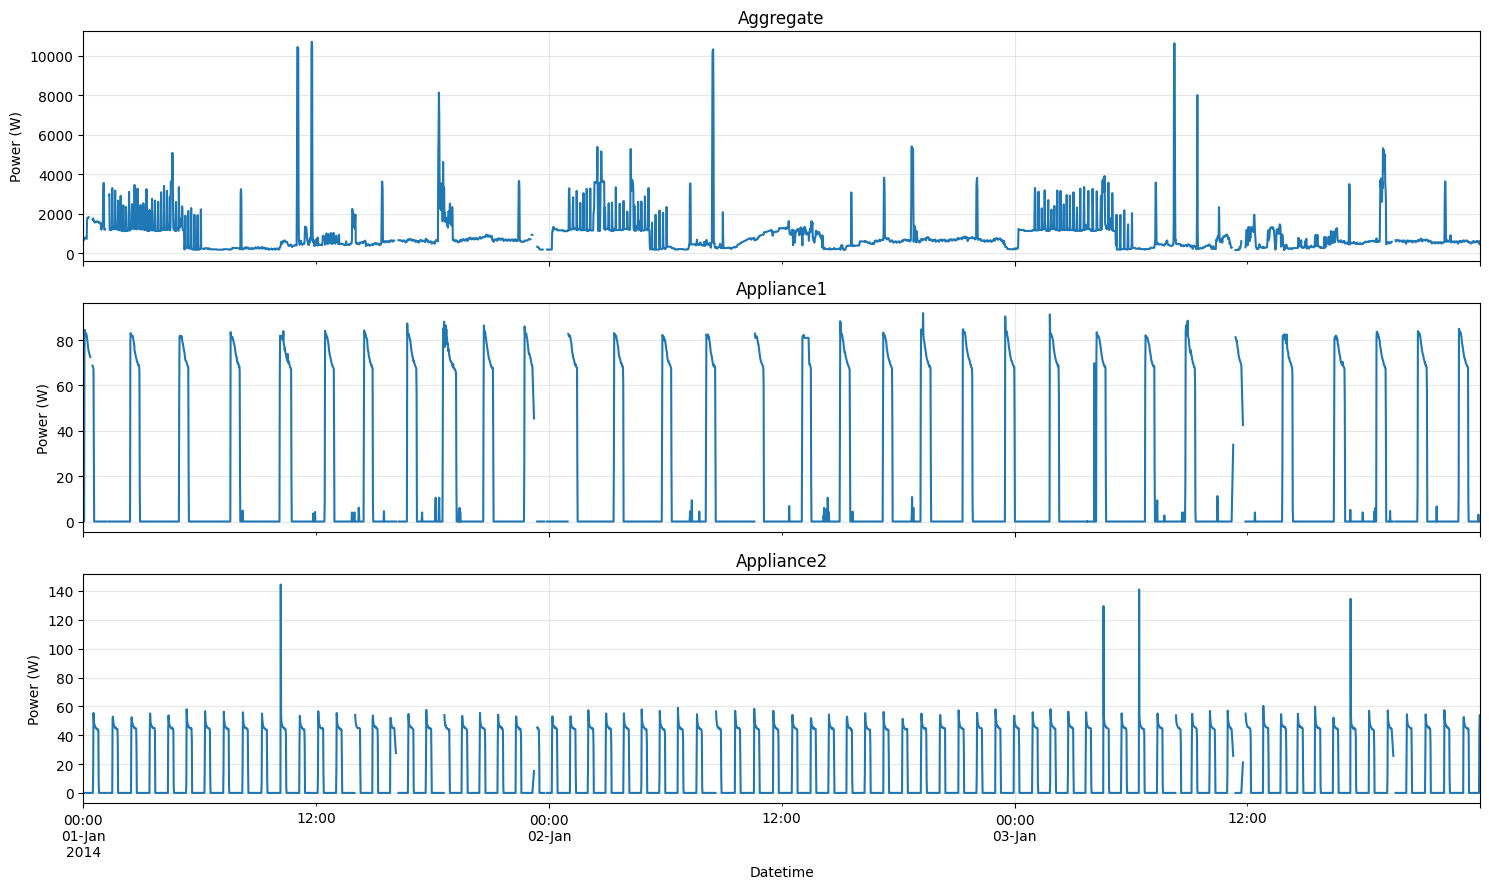

In [ ]:
import matplotlib.pyplot as plt

cols = ['Aggregate', 'Appliance1', 'Appliance2']

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

for ax, col in zip(axes, cols):
    df_final[col].loc['2014-01':'2014-01-03'].plot(ax=ax)
    ax.set_title(col)
    ax.set_ylabel('Power (W)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
appliances = [f'Appliance{i}' for i in range(1, 10)]

print("Final missing-value percentage:")
display((df_final.isna().mean() * 100).round(2))

print("\nFinal appliance statistics:")
display(df_final[appliances].describe().T)

Final missing-value percentage:


Aggregate                12.45
Appliance1               12.38
Appliance2               12.43
Appliance3               12.45
Appliance4               12.34
Appliance5               12.79
Appliance6               12.34
Appliance7               12.30
Appliance8               12.36
Appliance9               22.54
Aggregate_long_outage     0.00
dtype: float64


Final appliance statistics:


,count,mean,std,min,25%,50%,75%,max
Appliance1,806162.0,17.304738,31.532992,0.0,0.0,0.0,0.000,154.000000
Appliance2,805687.0,16.456491,22.502387,0.0,0.0,0.0,45.250,149.666667
Appliance3,805524.0,29.008133,35.550796,0.0,0.0,0.0,69.625,195.750000
Appliance4,806454.0,0.767764,24.286562,0.0,0.0,0.0,0.000,1367.750000
Appliance5,802397.0,8.772386,117.526030,0.0,0.0,0.0,0.000,2305.166667
Appliance6,806466.0,8.896005,135.321396,0.0,0.0,0.0,0.000,2273.571429
Appliance7,806847.0,2.378237,7.975504,0.0,0.0,0.0,0.000,42.625000
Appliance8,806301.0,5.820570,12.448167,0.0,0.0,0.0,0.000,53.625000
Appliance9,712662.0,74.321099,256.937264,0.0,1.0,1.0,1.000,1043.888889


In [ ]:
appliances = [f'Appliance{i}' for i in range(1, 10)]

valid = df_final['Aggregate'].notna() & df_final[appliances].notna().all(axis=1)

agg = df_final.loc[valid, 'Aggregate']
appliance_sum = df_final.loc[valid, appliances].sum(axis=1)

print("Rows compared:", len(agg))
print("Correlation:", round(agg.corr(appliance_sum), 3))
print("Mean absolute difference (W):",
      round((agg - appliance_sum).abs().mean(), 2))
print("Mean Aggregate (W):", round(agg.mean(), 2))
print("Mean appliance sum (W):", round(appliance_sum.mean(), 2))

Rows compared: 703246
Correlation: 0.43
Mean absolute difference (W): 329.59
Mean Aggregate (W): 487.38
Mean appliance sum (W): 164.67


In [ ]:
print("Raw window:", raw_window.shape)
print("Cleaned window:", clean_window.shape)

print("\nCleaned interval check:")
print(
    clean_window.index.to_series()
    .diff().dropna().value_counts().head()
)

print("\nMissing values after cleaning:")
print(clean_window.isna().sum())

print("\nDuplicate timestamps:")
print(clean_window.index.duplicated().sum())

Raw window: (7922823, 13)
Cleaned window: (920030, 11)

Cleaned interval check:
Datetime
0 days 00:01:00    920029
Name: count, dtype: int64

Missing values after cleaning:
Aggregate                114544
Appliance1               117071
Appliance2               117936
Appliance3               116010
Appliance4               115414
Appliance5               122956
Appliance6               115389
Appliance7               114541
Appliance8               116196
Appliance9               212379
Aggregate_long_outage         0
dtype: int64

Duplicate timestamps:
0


In [ ]:
import pandas as pd

df_final = df_clean_final.copy()

# Ensure datetime index
df_final.index = pd.to_datetime(df_final.index)
df_final = df_final.sort_index()

# Power columns
cols = [
    'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3',
    'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7',
    'Appliance8', 'Appliance9'
]

# Fill only short internal gaps (maximum 5 consecutive minutes)
df_final[cols] = df_final[cols].interpolate(
    method='time',
    limit=5,
    limit_area='inside'
)

# Flag remaining missing readings as potential longer gaps
df_final['Long_Outage_Flag'] = df_final[cols].isna().any(axis=1)

# Final validation
print("Final shape:", df_final.shape)
print("Duplicate timestamps:", df_final.index.duplicated().sum())
print("Chronological:", df_final.index.is_monotonic_increasing)
print("\nRemaining missing values:")
print(df_final[cols].isna().sum())
print("\nRows flagged for potential outages:",
      df_final['Long_Outage_Flag'].sum())

df_final.to_csv("house1_cleaned_final.csv")
print("\nFinal dataset saved.")

Final shape: (920031, 12)
Duplicate timestamps: 0
Chronological: True

Remaining missing values:
Aggregate     112404
Appliance1    113070
Appliance2    113539
Appliance3    113708
Appliance4    112811
Appliance5    116837
Appliance6    112757
Appliance7    112383
Appliance8    112924
Appliance9    206655
dtype: int64

Rows flagged for potential outages: 208243

Final dataset saved.


In [ ]:
import pandas as pd
import os

df = pd.read_csv("cleaned_power_data.csv", parse_dates=["Datetime"])
df = df.set_index("Datetime").sort_index()

print("Final shape:", df.shape)
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Chronological:", df.index.is_monotonic_increasing)
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(2))
print("\nSaved file exists:", os.path.exists("cleaned_power_data.csv"))

Final shape: (920031, 11)
Duplicate timestamps: 0
Chronological: True

Missing values (%):
Aggregate                12.45
Appliance1               12.38
Appliance2               12.43
Appliance3               12.45
Appliance4               12.34
Appliance5               12.79
Appliance6               12.34
Appliance7               12.30
Appliance8               12.36
Appliance9               22.54
Aggregate_long_outage     0.00
dtype: float64

Saved file exists: True


In [ ]:
print("Long-outage flag counts:")
print(df["Aggregate_long_outage"].value_counts())

print("\nMissing values in Aggregate:")
print(df["Aggregate"].isna().sum())

print("\nTime range:")
print(df.index.min(), "to", df.index.max())

Long-outage flag counts:
Aggregate_long_outage
False    805487
True     114544
Name: count, dtype: int64

Missing values in Aggregate:
114544

Time range:
2013-10-09 14:06:00 to 2015-07-10 11:56:00


### Data Cleaning Pipeline — House 1

**1. Timestamp validation and ordering:** Timestamps were converted to datetime format and readings were sorted chronologically.

**2. Duplicate handling:** Duplicate timestamps were removed using a documented rule: retain the first reading for each timestamp.

**3. One-minute resampling:** Readings were resampled to regular one-minute intervals to support consistent time-series analysis.

**4. Missing-value handling:** Short internal gaps were interpolated using time-based interpolation. Longer outages were flagged rather than automatically filled, avoiding unsupported assumptions about power consumption during outages.

**5. Outlier inspection:** Extreme power readings were identified and reviewed. Values were not assumed to be erroneous solely because they were unusually high.

**6. Validation:** The final dataset was checked for duplicate timestamps, chronological ordering, remaining missing values, and regular sampling intervals.

**7. Visual comparison:** Aggregate power, Appliance1, and Appliance2 were plotted before and after cleaning to assess the effects of the cleaning process.

**Limitation:** Missing values remain where readings are unavailable or outages are flagged. The cleaned dataset therefore preserves uncertainty rather than claiming complete recovery of missing measurements.